In [2]:
%pip install imblearn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    average_precision_score, roc_auc_score,
    precision_recall_curve, confusion_matrix
)

from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline


In [4]:
# ==========================================
# 1. Load the real dataset
# ==========================================

dataset = fetch_ucirepo(id=468)
X = dataset.data.features.copy()
y = dataset.data.targets["Revenue"].astype(int)
display(X.head())
display(y.head())

print("Original class distribution:")
print(y.value_counts().sort_index())


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True


0    0
1    0
2    0
3    0
4    0
Name: Revenue, dtype: int64

Original class distribution:
Revenue
0    10422
1     1908
Name: count, dtype: int64


In [5]:
# ==========================================
# 2. Train / Validation / Test
# ==========================================

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.25,
    stratify=y_temp,
    random_state=42
)

print("\nTraining distribution:")
print(y_train.value_counts().sort_index())


Training distribution:
Revenue
0    6253
1    1145
Name: count, dtype: int64


In [6]:

# ==========================================
# 3. Demonstrate Resampling
# ==========================================

ros = RandomOverSampler(random_state=42)
rus = RandomUnderSampler(random_state=42)

_, y_ros = ros.fit_resample(X_train, y_train)
_, y_rus = rus.fit_resample(X_train, y_train)

print("\nOriginal Train:")
print(y_train.value_counts().sort_index())

print("\nAfter Oversampling:")
print(pd.Series(y_ros).value_counts().sort_index())

print("\nAfter Undersampling:")
print(pd.Series(y_rus).value_counts().sort_index())

# The above is only to demonstrate class counts.
# Actual training below uses independent pipelines.




Original Train:
Revenue
0    6253
1    1145
Name: count, dtype: int64

After Oversampling:
Revenue
0    6253
1    6253
Name: count, dtype: int64

After Undersampling:
Revenue
0    1145
1    1145
Name: count, dtype: int64


In [7]:
# ==========================================
# 4. Preprocessing
# ==========================================

categorical_cols = [
    "Month", "OperatingSystems",
    "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]

numeric_cols = [
    col for col in X.columns
    if col not in categorical_cols
]


def build_model(sampler):

    preprocessor = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_cols),
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_cols)
    ])

    return ImbPipeline([
        ("preprocessor", preprocessor),
        ("sampler", sampler),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ])


In [8]:

# ==========================================
# 5. Build Three Models
# ==========================================

models = {
    "Baseline": build_model("passthrough"),

    "Random Oversampling": build_model(
        RandomOverSampler(random_state=42)
    ),

    "Random Undersampling": build_model(
        RandomUnderSampler(random_state=42)
    )
}

In [9]:
# ==========================================
# 6. Evaluation Function
# ==========================================

def evaluate(model, X_eval, y_eval, threshold=0.5):

    probabilities = model.predict_proba(X_eval)[:, 1]

    predictions = (
        probabilities >= threshold
    ).astype(int)

    return {
        "Accuracy": accuracy_score(y_eval, predictions),
        "Precision": precision_score(
            y_eval, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_eval, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_eval, predictions, zero_division=0
        ),
        "AP": average_precision_score(
            y_eval, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_eval, probabilities
        )
    }

In [10]:
# ==========================================
# 7. Train and Compare on Validation
# ==========================================

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    scores = evaluate(
        model, X_val, y_val, threshold=0.5
    )

    results.append({
        "Method": name,
        **scores
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1",
    ascending=False
)


Validation Results:


,Method,Accuracy,Precision,Recall,F1,AP,ROC-AUC
1,Random Oversampling,0.835,0.480,0.780,0.594,0.671,0.901
2,Random Undersampling,0.833,0.475,0.790,0.593,0.666,0.897
0,Baseline,0.886,0.746,0.402,0.522,0.660,0.890


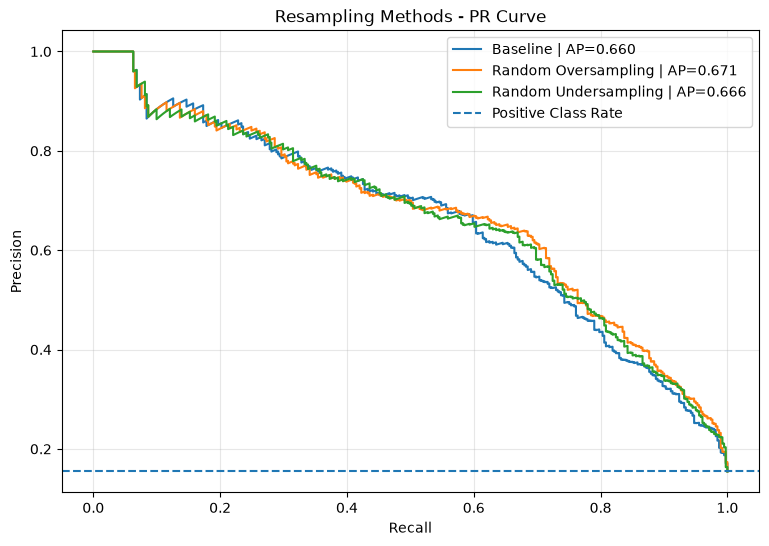

In [11]:
print("\nValidation Results:")
display(results_df.round(3))


# ==========================================
# 8. Precision-Recall Curves
# ==========================================

plt.figure(figsize=(9, 6))

for name, model in models.items():

    probabilities = model.predict_proba(X_val)[:, 1]

    precision, recall, _ = precision_recall_curve(
        y_val, probabilities
    )

    ap = average_precision_score(
        y_val, probabilities
    )

    plt.plot(
        recall, precision,
        label=f"{name} | AP={ap:.3f}"
    )

plt.axhline(
    y=y_val.mean(),
    linestyle="--",
    label="Positive Class Rate"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Resampling Methods - PR Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



In [12]:

# ==========================================
# 9. Select Best Model Using Validation F1
# ==========================================

best_name = results_df.iloc[0]["Method"]
best_model = models[best_name]

print("\nBest method on Validation:", best_name)




Best method on Validation: Random Oversampling


In [13]:



# ==========================================
# 10. Final Independent Test
# ==========================================

test_scores = evaluate(
    best_model,
    X_test,
    y_test,
    threshold=0.5
)

print("\nFinal Test Results:")
display(pd.Series(test_scores).round(3))

test_predictions = (
    best_model.predict_proba(X_test)[:, 1] >= 0.5
).astype(int)

print("\nTest Confusion Matrix:")
print(confusion_matrix(y_test, test_predictions))



Final Test Results:


Accuracy     0.835
Precision    0.478
Recall       0.751
F1           0.585
AP           0.622
ROC-AUC      0.888
dtype: float64


Test Confusion Matrix:
[[1771  313]
 [  95  287]]


Best Baseline Threshold: 0.24
Best Validation F1: 0.633

Selected Threshold Results:


,Threshold,Accuracy,Precision,Recall,F1
5,0.1,0.698,0.327,0.900,0.479
15,0.2,0.860,0.535,0.717,0.613
25,0.3,0.892,0.685,0.559,0.616
35,0.4,0.888,0.711,0.459,0.558
45,0.5,0.886,0.746,0.402,0.522


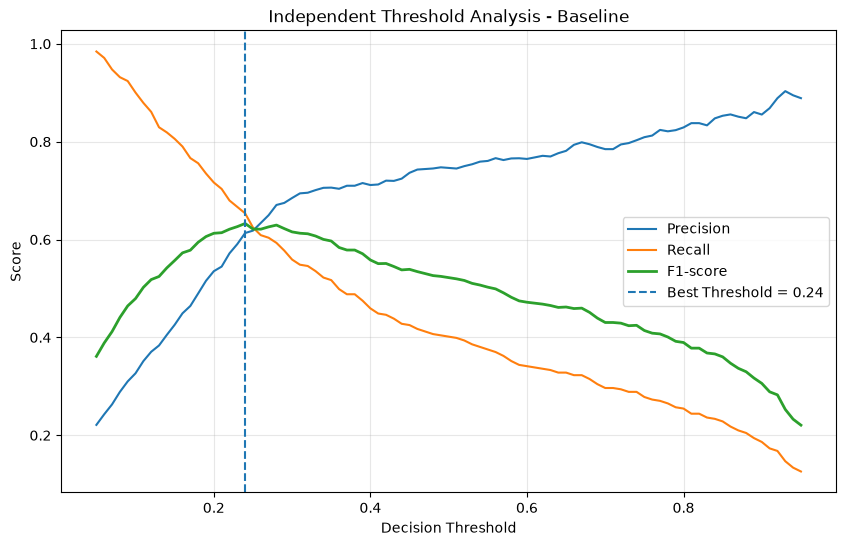

In [14]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

# ------------------------------------------
# 1. Use validation data only
# ------------------------------------------

baseline = models["Baseline"]

baseline_probs = baseline.predict_proba(X_val)[:, 1]

thresholds = np.round(
    np.arange(0.05, 0.951, 0.01), 2
)

# ------------------------------------------
# 2. Evaluate different thresholds
# ------------------------------------------

def calculate_metrics(y_true, probs, threshold):

    predictions = (probs >= threshold).astype(int)

    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        )
    }


baseline_rows = []

for threshold in thresholds:

    scores = calculate_metrics(
        y_val, baseline_probs, threshold
    )

    baseline_rows.append({
        "Threshold": threshold,
        **scores
    })

baseline_results = pd.DataFrame(baseline_rows)

# ------------------------------------------
# 3. Find best threshold using validation F1
# ------------------------------------------

best_idx = baseline_results["F1"].idxmax()

best_baseline = baseline_results.loc[best_idx]

print("Best Baseline Threshold:",
      best_baseline["Threshold"])

print("Best Validation F1:",
      round(best_baseline["F1"], 3))

print("\nSelected Threshold Results:")

display(
    baseline_results[
        baseline_results["Threshold"].isin(
            [0.1, 0.2, 0.3, 0.4, 0.5]
        )
    ].round(3)
)

# ------------------------------------------
# 4. Plot threshold impact
# ------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    baseline_results["Threshold"],
    baseline_results["Precision"],
    label="Precision"
)

plt.plot(
    baseline_results["Threshold"],
    baseline_results["Recall"],
    label="Recall"
)

plt.plot(
    baseline_results["Threshold"],
    baseline_results["F1"],
    label="F1-score",
    linewidth=2
)

plt.axvline(
    x=best_baseline["Threshold"],
    linestyle="--",
    label=f"Best Threshold = {best_baseline['Threshold']:.2f}"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Independent Threshold Analysis - Baseline")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Fixed Threshold Comparison (0.5):


,Method,Threshold,Accuracy,Precision,Recall,F1
136,Random Oversampling,0.5,0.835,0.480,0.780,0.594
227,Random Undersampling,0.5,0.833,0.475,0.790,0.593
45,Baseline,0.5,0.886,0.746,0.402,0.522



Optimized Threshold Comparison:


,Method,Threshold,Accuracy,Precision,Recall,F1
149,Random Oversampling,0.63,0.889,0.627,0.693,0.658
243,Random Undersampling,0.66,0.889,0.634,0.664,0.649
19,Baseline,0.24,0.883,0.613,0.654,0.633


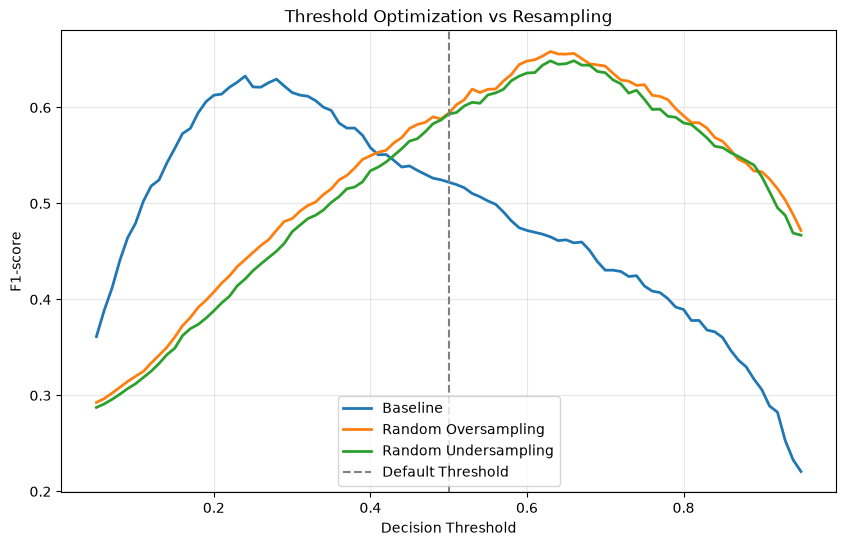

In [15]:

# ------------------------------------------
# 1. Get validation probabilities
# ------------------------------------------

validation_probs = {
    name: model.predict_proba(X_val)[:, 1]
    for name, model in models.items()
}

# ------------------------------------------
# 2. Evaluate all methods and thresholds
# ------------------------------------------

all_rows = []

for name, probs in validation_probs.items():

    for threshold in thresholds:

        scores = calculate_metrics(
            y_val, probs, threshold
        )

        all_rows.append({
            "Method": name,
            "Threshold": threshold,
            **scores
        })

comparison_df = pd.DataFrame(all_rows)

# ------------------------------------------
# 3. Compare methods at fixed threshold
# ------------------------------------------

fixed_results = comparison_df[
    np.isclose(comparison_df["Threshold"], 0.5)
].copy()

print("Fixed Threshold Comparison (0.5):")

display(
    fixed_results.sort_values(
        "F1", ascending=False
    ).round(3)
)

# ------------------------------------------
# 4. Find best threshold for each method
# ------------------------------------------

best_indices = comparison_df.groupby(
    "Method"
)["F1"].idxmax()

best_results = comparison_df.loc[
    best_indices
].copy()

best_results = best_results.sort_values(
    "F1", ascending=False
)

print("\nOptimized Threshold Comparison:")

display(best_results.round(3))

# ------------------------------------------
# 5. Plot F1 vs Threshold for all methods
# ------------------------------------------

plt.figure(figsize=(10, 6))

for name in models.keys():

    data = comparison_df[
        comparison_df["Method"] == name
    ]

    plt.plot(
        data["Threshold"],
        data["F1"],
        label=name,
        linewidth=2
    )

plt.axvline(
    0.5,
    linestyle="--",
    color="gray",
    label="Default Threshold"
)

plt.xlabel("Decision Threshold")
plt.ylabel("F1-score")
plt.title("Threshold Optimization vs Resampling")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [16]:

# ------------------------------------------
# Select best model + threshold using F1
# ------------------------------------------

selected = best_results.iloc[0]

best_method = selected["Method"]
best_threshold = float(selected["Threshold"])

best_model = models[best_method]

print("Selected Method:", best_method)
print("Selected Threshold:", best_threshold)

# ------------------------------------------
# Independent test evaluation
# ------------------------------------------

test_probs = best_model.predict_proba(X_test)[:, 1]

test_scores = calculate_metrics(
    y_test, test_probs, best_threshold
)

test_scores["AP"] = average_precision_score(
    y_test, test_probs
)

test_scores["ROC-AUC"] = roc_auc_score(
    y_test, test_probs
)

print("\nFinal Test Results:")
display(pd.Series(test_scores).round(3))

test_predictions = (
    test_probs >= best_threshold
).astype(int)

print("\nFinal Confusion Matrix:")
print(confusion_matrix(y_test, test_predictions))


Selected Method: Random Oversampling
Selected Threshold: 0.63

Final Test Results:


Accuracy     0.878
Precision    0.599
Recall       0.644
F1           0.620
AP           0.622
ROC-AUC      0.888
dtype: float64


Final Confusion Matrix:
[[1919  165]
 [ 136  246]]



<div dir="rtl" style="text-align:right; line-height:2.2;
font-family:Tahoma,sans-serif;">

<h2>📊 تحلیل نهایی نتایج طبقه‌بندی داده‌های نامتوازن</h2>

<h3>۱. معرفی آزمایش</h3>

<p>
در این آزمایش، عملکرد الگوریتم
<b>Logistic Regression</b>
در مجموعه‌داده واقعی
<b>Online Shoppers Purchasing Intention</b>
بررسی شد.
</p>

<p>
هدف اصلی، مطالعه تأثیر مستقل و ترکیبی
<b>تنظیم آستانه تصمیم‌گیری (Decision Threshold)</b>
و روش‌های متوازن‌سازی داده‌ها شامل
<b>Random Oversampling</b>
و
<b>Random Undersampling</b>
بر عملکرد مدل در شناسایی کلاس اقلیت بود.
</p>

<p>
برای جلوگیری از نشت اطلاعات
(Data Leakage)،
مجموعه‌داده به سه بخش آموزش
(Train)، اعتبارسنجی (Validation)
و آزمون (Test) تقسیم شد.
انتخاب مدل و آستانه تصمیم‌گیری
براساس داده‌های اعتبارسنجی صورت گرفت
و ارزیابی نهایی روی مجموعه آزمون انجام شد.
</p>

<h3>۲. نتایج بهینه‌سازی Threshold روی Validation</h3>

<p>
مقایسه روش‌های مختلف نشان داد که
تنظیم Threshold حتی بدون انجام
متوازن‌سازی داده‌ها نیز می‌تواند
عملکرد مدل را بهبود دهد.
</p>

<table style="border-collapse:collapse;width:100%;text-align:center;"
border="1" cellpadding="8">
<tr>
<th>روش</th>
<th>Threshold بهینه</th>
<th>F1-score</th>
</tr>
<tr>
<td>Baseline</td>
<td>0.24</td>
<td>0.633</td>
</tr>
<tr>
<td>Random Oversampling</td>
<td>0.63</td>
<td><b>0.658</b></td>
</tr>
<tr>
<td>Random Undersampling</td>
<td>0.66</td>
<td>0.649</td>
</tr>
</table>

<p>
در مدل Baseline، کاهش آستانه از
۰٫۵ به ۰٫۲۴ باعث افزایش
F1-score از ۰٫۵۲۲ به ۰٫۶۳۳ شد.
این بهبود بدون تغییر داده‌های آموزشی
یا آموزش مجدد مدل به دست آمد.
</p>

<p>
بااین‌حال، پس از بهینه‌سازی آستانه،
روش Random Oversampling
با مقدار F1 برابر ۰٫۶۵۸
بهترین نتیجه را در مجموعه اعتبارسنجی ثبت کرد.
بنابراین این مدل با Threshold برابر ۰٫۶۳
برای ارزیابی نهایی انتخاب شد.
</p>

<h3>۳. نتایج نهایی روی Test</h3>

<p>
مدل منتخب
<b>Random Oversampling</b>
با آستانه
<b>۰٫۶۳</b>
روی مجموعه آزمون مستقل ارزیابی شد.
</p>

<table style="border-collapse:collapse;width:100%;text-align:center;"
border="1" cellpadding="8">
<tr>
<th>معیار</th>
<th>مقدار</th>
</tr>
<tr><td>Accuracy</td><td>0.878</td></tr>
<tr><td>Precision</td><td><b>0.599</b></td></tr>
<tr><td>Recall</td><td>0.644</td></tr>
<tr><td>F1-score</td><td><b>0.620</b></td></tr>
<tr><td>Average Precision</td><td>0.622</td></tr>
<tr><td>ROC-AUC</td><td>0.888</td></tr>
</table>

<h3>۴. تحلیل دقیق Precision</h3>

<p>
معیار Precision نشان می‌دهد از میان
نمونه‌هایی که مدل آن‌ها را
مثبت یا خریدار پیش‌بینی کرده است،
چه نسبتی واقعاً به کلاس مثبت تعلق دارند.
</p>

<p>
براساس ماتریس درهم‌ریختگی نهایی،
مدل ۲۴۶ نمونه مثبت را درست شناسایی کرده
و ۱۶۵ نمونه منفی را
به‌اشتباه مثبت تشخیص داده است.
</p>

<p>
<b>Precision = TP / (TP + FP)</b>
</p>

<p dir="ltr" style="text-align:center;">
Precision = 246 / (246 + 165) = 0.599
</p>

<p>
بنابراین Precision برابر
<b>۵۹٫۹ درصد</b>
است؛ یعنی از هر ۱۰۰ کاربری
که مدل خریدار پیش‌بینی می‌کند،
به‌طور متوسط حدود ۶۰ نفر واقعاً خریدار هستند
و حدود ۴۰ نفر به‌اشتباه خریدار تشخیص داده شده‌اند.
</p>

<p>
در خروجی نخست Test،
Precision برابر ۴۷٫۸ درصد بود.
پس از انتخاب Threshold برابر ۰٫۶۳،
Precision به ۵۹٫۹ درصد افزایش یافت؛
یعنی حدود
<b>۱۲٫۱ واحد درصد بهبود</b>.
</p>

<p>
این نتیجه نشان می‌دهد که آستانه جدید،
تعداد پیش‌بینی‌های مثبت اشتباه را کاهش داده
و قابلیت اعتماد به پیش‌بینی‌های مثبت را
افزایش داده است.
بااین‌حال، هنوز حدود ۴۰ درصد
هشدارهای مثبت مدل اشتباه هستند.
</p>

<h3>۵. تحلیل Recall و رابطه آن با Precision</h3>

<p>
Recall نشان‌دهنده نسبت نمونه‌های مثبت واقعی
است که مدل موفق به شناسایی آن‌ها شده است.
</p>

<p dir="ltr" style="text-align:center;">
Recall = 246 / (246 + 136) = 0.644
</p>

<p>
مدل توانسته
<b>۶۴٫۴ درصد خریداران واقعی</b>
را شناسایی کند.
بنابراین حدود ۳۵٫۶ درصد
خریداران واقعی شناسایی نشده‌اند.
</p>

<p>
در خروجی نخست،
Recall برابر ۷۵٫۱ درصد بود؛
اما در مدل نهایی به ۶۴٫۴ درصد کاهش یافت.
</p>

<p>
این تغییر نشان‌دهنده وجود
<b>مبادله میان Precision و Recall</b>
است؛ یعنی با سخت‌گیرانه‌تر کردن
شرط مثبت بودن نمونه‌ها،
تعداد پیش‌بینی‌های اشتباه مثبت کاهش یافته،
اما بخشی از مثبت‌های واقعی نیز
از دست رفته‌اند.
</p>

<h3>۶. تحلیل Confusion Matrix</h3>

<p>
ماتریس درهم‌ریختگی مدل نهایی به شکل زیر است:
</p>

<table style="border-collapse:collapse;width:100%;text-align:center;"
border="1" cellpadding="8">
<tr>
<th>وضعیت واقعی</th>
<th>پیش‌بینی منفی</th>
<th>پیش‌بینی مثبت</th>
</tr>
<tr>
<td>واقعاً منفی</td>
<td>TN = 1919</td>
<td>FP = 165</td>
</tr>
<tr>
<td>واقعاً مثبت</td>
<td>FN = 136</td>
<td>TP = 246</td>
</tr>
</table>

<p>
از مجموع ۳۸۲ خریدار واقعی،
مدل ۲۴۶ نفر را شناسایی کرده
و ۱۳۶ نفر را از دست داده است.
</p>

<p>
همچنین از مجموع ۲۰۸۴ کاربر غیرخریدار،
۱۹۱۹ نفر به‌درستی غیرخریدار
و ۱۶۵ نفر به‌اشتباه خریدار تشخیص داده شده‌اند.
</p>

<p>
در مقایسه با خروجی نخست Test،
تعداد False Positive از ۳۱۳ به ۱۶۵ کاهش یافته،
اما تعداد False Negative از ۹۵ به ۱۳۶
افزایش پیدا کرده است.
</p>

<p>
بنابراین مدل نهایی
<b>۱۴۸ پیش‌بینی مثبت اشتباه کمتر</b>
داشته است،
اما در مقابل
<b>۴۱ خریدار واقعی بیشتر را از دست داده است</b>.
</p>

<p>
مناسب بودن این مبادله به هدف کاربردی
و هزینه هر نوع خطا بستگی دارد.
</p>

<h3>۷. تحلیل Accuracy و F1-score</h3>

<p>
مقدار Accuracy در مدل نهایی برابر
<b>۸۷٫۸ درصد</b>
است؛ یعنی ۸۷٫۸ درصد
تمام نمونه‌های آزمون درست طبقه‌بندی شده‌اند.
</p>

<p>
بااین‌حال، به دلیل نامتوازن بودن
تعداد کلاس‌ها،
Accuracy به‌تنهایی نمی‌تواند
معیار کافی برای ارزیابی مدل باشد.
</p>

<p>
مقدار F1-score برابر
<b>۰٫۶۲۰</b>
نشان می‌دهد مدل توانسته تعادل
بهتری میان Precision و Recall
نسبت به خروجی نخست Test
با F1 برابر ۰٫۵۸۵ ایجاد کند.
</p>

<p>
بنابراین تنظیم آستانه تصمیم‌گیری
باعث افزایش Accuracy و F1-score
در ارزیابی نهایی شده است.
</p>

<h3>۸. تحلیل Average Precision و ROC-AUC</h3>

<p>
مقدار
<b>ROC-AUC برابر ۰٫۸۸۸</b>
نشان‌دهنده قدرت تفکیک مناسب
مدل میان خریداران و غیرخریداران است.
</p>

<p>
همچنین مقدار
<b>Average Precision برابر ۰٫۶۲۲</b>
در مقایسه با نرخ پایه کلاس مثبت
(حدود ۰٫۱۵۵)،
نشان‌دهنده عملکرد بهتر مدل
در رتبه‌بندی نمونه‌های مثبت است.
</p>

<p>
ثابت ماندن این دو معیار میان خروجی‌های
آزمون نشان می‌دهد که تغییر آستانه،
در صورت ثابت بودن مدل و امتیازهای پیش‌بینی،
عملکرد رتبه‌بندی آن را تغییر نمی‌دهد.
</p>

<h3>۹. مقایسه Validation و Test</h3>

<p>
مقدار F1-score مدل منتخب روی Validation
برابر ۰٫۶۵۸ بود،
درحالی‌که مقدار آن روی Test
به ۰٫۶۲۰ رسید.
</p>

<p>
همچنین AP از ۰٫۶۷۱ در Validation
به ۰٫۶۲۲ در Test
و ROC-AUC از ۰٫۹۰۱
به ۰٫۸۸۸ رسید.
</p>

<p>
این اختلاف‌ها می‌توانند ناشی از
تغییر ترکیب نمونه‌ها،
نوسانات آماری و انتخاب مدل
براساس مجموعه اعتبارسنجی باشند.
برای بررسی پایداری و تعمیم‌پذیری نتایج،
آزمایش‌های تکرارشونده و
Cross-Validation ضروری هستند.
</p>

<h3>۱۰. نتیجه‌گیری نهایی</h3>

<p>
نتایج این پژوهش اولیه نشان دادند که
<b>تنظیم Threshold و روش‌های Resampling
هر دو می‌توانند بر عملکرد طبقه‌بندی
داده‌های نامتوازن تأثیر بگذارند.</b>
</p>

<p>
تنظیم مستقل Threshold در مدل Baseline
باعث افزایش قابل‌توجه F1-score شد
و نشان داد که برای بهبود عملکرد
همیشه نیاز به متوازن‌سازی داده‌ها نیست.
</p>

<p>
بااین‌حال، در مجموعه اعتبارسنجی،
ترکیب
<b>Random Oversampling و Threshold برابر ۰٫۶۳</b>
بهترین عملکرد را براساس F1-score ثبت کرد.
</p>

<p>
در ارزیابی نهایی روی Test،
این مدل به
<b>Precision برابر ۵۹٫۹ درصد،
Recall برابر ۶۴٫۴ درصد
و F1-score برابر ۶۲ درصد</b>
دست یافت.
</p>

<p>
افزایش Precision نسبت به خروجی نخست
نشان داد که تنظیم آستانه مناسب
می‌تواند تعداد هشدارهای اشتباه را کاهش دهد؛
اما این بهبود با کاهش Recall همراه بود.
</p>

<p>
در مجموع، انتخاب روش مناسب باید
با توجه به هدف کاربردی،
اهمیت شناسایی کلاس اقلیت،
هزینه False Positive و False Negative
و تعادل میان Precision و Recall انجام شود.
</p>

<p>
نتایج فعلی از نظر آموزشی و پژوهشی
امیدوارکننده هستند؛
بااین‌حال، برای ادعای برتری قطعی
یک روش، انجام اعتبارسنجی متقاطع،
تحلیل آماری و آزمایش روی مجموعه‌داده‌های
بیشتر ضروری است.
</p>

<h3>۱۱. مسیر ادامه پژوهش و Explainable AI</h3>

<p>
در ادامه می‌توان روش‌های پیشرفته‌تری
مانند SMOTE و Class Weight
را با مدل Baseline و روش‌های
نمونه‌برداری فعلی مقایسه کرد.
</p>

<p>
سپس با استفاده از روش‌های
Explainable AI مانند SHAP،
تغییرات اهمیت ویژگی‌ها و پایداری
توضیحات مدل در اثر روش‌های
متوازن‌سازی داده‌ها بررسی خواهد شد.
</p>

<p>
این تحلیل می‌تواند مشخص کند که
آیا بهبود عملکرد پیش‌بینی
با تغییر در رفتار و توضیح‌پذیری مدل
همراه است یا خیر.
</p>

<hr>

<p style="color:gray;font-size:13px;">
<b>نکته روش‌شناسی:</b>
مقادیر بهینه Threshold و انتخاب
روش Random Oversampling
بر اساس Validation تعیین شده‌اند.
برای حفظ استقلال ارزیابی،
نباید از نتایج Test برای تنظیم مجدد
مدل یا آستانه تصمیم‌گیری استفاده شود.
همچنین مقایسه دو خروجی Test
با فرض یکسان بودن مدل و نمونه‌های آزمون
انجام شده است.
</p>

</div>
